# 14 — Candidate QA regression comparison

Run after notebook 13. This is a PyTorch CPU comparison of the original baseline, continued-training control, and geometry candidate using their frozen validation thresholds. It does not overwrite the app ONNX, retrain, retune, or publish a model.

Checks include all labelled phone images in training/data/raw plus exactly the 12 saved false_positive_imgs fixtures. Those fixtures were selected from validation failures, so success on them is a regression check rather than independent evidence of generalisation.

The stored phone files include QA scans that previously failed even though the physical camera flow passed QA. Report those file results honestly and record camera-flow QA separately. Type matches alone do not establish correct boxes or capture quality.

Run sections in order. Results are saved only under the new experiment directory. Deployment/export should follow only after reviewing validation, development-test and QA reports. Existing notebooks 09/10/11 still point to the original baseline.

In [1]:
from pathlib import Path
from collections import Counter
import sys
import json
import hashlib
import time
import random
import html

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, HTML

PROJECT = Path("/home/joe/PycharmProjects/id-capture")
SOURCE = PROJECT / "training/vendor/YOLOX"
for directory in (str(PROJECT), str(SOURCE)):
    if directory not in sys.path:
        sys.path.insert(0, directory)
from training.yolox_workflow import (
    make_model, predict_records, summarize, audit, save_json,
    letterbox, show_progress, NAMES,
)

def sha256_file(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()

def table(rows):
    if not rows:
        print("No rows.")
        return
    columns = list(rows[0])
    head = "".join(f"<th>{html.escape(str(c))}</th>" for c in columns)
    body = "".join(
        "<tr>" + "".join(f"<td>{html.escape(str(row[c]))}</td>" for c in columns) + "</tr>"
        for row in rows
    )
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))

ROOT = PROJECT / "training/runs/yolox_geometry_experiments"
experiment = json.loads((ROOT / "latest_completed.json").read_text())
EXPERIMENT = Path(experiment["experiment"])
MANIFEST_PATH = Path(experiment["manifest"])
assert sha256_file(MANIFEST_PATH) == experiment["manifest_sha256"], "Dataset changed."
manifest = json.loads(MANIFEST_PATH.read_text())
audit(manifest["records"])
CHECKPOINTS = {name: Path(path) for name,path in experiment["checkpoints"].items()}
assert all(path.is_file() for path in CHECKPOINTS.values())
assert sha256_file(CHECKPOINTS["Baseline"]) == experiment["baseline_sha256"]
SIZE, BATCH = experiment["size"], 16
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Experiment:", EXPERIMENT)
print("Device:", DEVICE)

from PIL import Image, ImageOps
from training.yolox_workflow import letterbox
from yolox.utils import postprocess
from id_capture.onnx_detector import read_bgr, document_result

DEVICE = "cpu"
assert (EXPERIMENT / "development_test_comparison.json").is_file(), "Finish notebook 13."
decision = json.loads((EXPERIMENT / "validation_decision.json").read_text())
assert decision["manifest_sha256"] == experiment["manifest_sha256"]
calibrations = {
    name: json.loads((EXPERIMENT / f"{name.lower()}_calibration.json").read_text())
    for name in CHECKPOINTS
}
for name,checkpoint in CHECKPOINTS.items():
    assert sha256_file(checkpoint) == calibrations[name]["checkpoint_sha256"]
    assert calibrations[name]["manifest_sha256"] == experiment["manifest_sha256"]
    assert sha256_file(checkpoint) == decision["checkpoint_hashes"][name]
print("CPU QA at fixed thresholds:", {name:cal["threshold"] for name,cal in calibrations.items()})
print("Validation geometry improvement:", decision["geometry_improves_over_baseline_and_control"])


train 13100 {('midv500', 'none'): 4292, ('midv500', 'driving_licence'): 2362, ('midv500', 'passport'): 2346, ('midv2019', 'none'): 1680, ('midv2019', 'driving_licence'): 960, ('midv2019', 'passport'): 960, ('midv2020', 'none'): 200, ('midv2020', 'passport'): 300}
val 4400 {('midv500', 'none'): 1511, ('midv500', 'passport'): 890, ('midv500', 'driving_licence'): 599, ('midv2019', 'none'): 600, ('midv2019', 'passport'): 360, ('midv2019', 'driving_licence'): 240, ('midv2020', 'none'): 100, ('midv2020', 'passport'): 100}
test 4500 {('midv500', 'passport'): 884, ('midv500', 'none'): 1537, ('midv500', 'driving_licence'): 579, ('midv2019', 'passport'): 360, ('midv2019', 'driving_licence'): 240, ('midv2019', 'none'): 600, ('midv2020', 'none'): 300}
PASS: no document design crosses splits; all images exist.
Experiment: /home/joe/PycharmProjects/id-capture/training/runs/yolox_geometry_experiments/20261022_170347_473302
Device: cuda
CPU QA at fixed thresholds: {'Baseline': 0.2, 'Control': 0.95, 'G

## Inventory: phone images plus 12 saved negatives
Expected phone labels come from folders. Saved negatives use the fixture manifest and are hash-checked. No images are added to training.

In [2]:
qa_samples = []
extensions = {".jpg",".jpeg",".png",".tif",".tiff",".bmp",".webp"}
for expected in (*NAMES,"none"):
    folder = PROJECT / "training/data/raw" / expected
    if folder.is_dir():
        for path in sorted(folder.iterdir()):
            if path.is_file() and path.suffix.lower() in extensions:
                qa_samples.append(dict(
                    key=f"phone/{expected}/{path.name}", path=path,
                    expected=expected, group="phone",
                ))
FIXTURES = PROJECT / "false_positive_imgs"
fixture_manifest = json.loads((FIXTURES / "manifest.json").read_text())
assert len(fixture_manifest["samples"]) == 12
for sample in fixture_manifest["samples"]:
    assert sample["expected"] == "none" and sample["split"] == "val"
    path = (FIXTURES / sample["file"]).resolve()
    assert path.is_relative_to(FIXTURES.resolve())
    assert sha256_file(path) == sample["sha256"], path
    qa_samples.append(dict(
        key=f'negative_fixtures/{sample["file"]}', path=path,
        expected="none", group="negative_fixtures",
    ))
assert len({sample["key"] for sample in qa_samples}) == len(qa_samples)
print("QA image counts:", dict(Counter(sample["group"] for sample in qa_samples)))


QA image counts: {'phone': 12, 'negative_fixtures': 12}


In [3]:
qa_rows, qa_predictions = [], {}
for name,checkpoint in CHECKPOINTS.items():
    model = make_model(checkpoint).cpu().eval()
    threshold = calibrations[name]["threshold"]
    for sample in qa_samples:
        image = read_bgr(sample["path"])
        height,width = image.shape[:2]
        tensor, ratio = letterbox(image, SIZE)
        with torch.inference_mode():
            output = postprocess(
                model(torch.from_numpy(tensor).unsqueeze(0)), 2, threshold, 0.65
            )[0]
        if output is None:
            boxes = np.empty((0,6), dtype=np.float32)
        else:
            array = output.numpy()
            coordinates = array[:,:4] / ratio
            coordinates[:,[0,2]] = coordinates[:,[0,2]].clip(0,width)
            coordinates[:,[1,3]] = coordinates[:,[1,3]].clip(0,height)
            boxes = np.column_stack((coordinates,array[:,4]*array[:,5],array[:,6]))
        result = document_result(boxes)
        qa_predictions[(name,sample["key"])] = boxes
        wrong_class = (
            sample["expected"] != "none"
            and any(NAMES[int(d[5])] != sample["expected"] for d in boxes)
        )
        qa_rows.append(dict(
            model=name, group=sample["group"], image=sample["key"],
            expected=sample["expected"], predicted=result["document_type"],
            confidence=result["detection_confidence"], threshold=threshold,
            detections=len(boxes), type_match=sample["expected"] == result["document_type"],
            detection_on_negative=sample["expected"] == "none" and len(boxes) > 0,
            wrong_class_box=bool(wrong_class),
            boxes=boxes.tolist(),
        ))
        del image
    del model
table([{k:v for k,v in row.items() if k != "boxes"} for row in qa_rows])
qa_summary = []
for name in CHECKPOINTS:
    for group in ("phone","negative_fixtures"):
        rows = [r for r in qa_rows if r["model"] == name and r["group"] == group]
        negatives = [r for r in rows if r["expected"] == "none"]
        qa_summary.append(dict(
            model=name, group=group, images=len(rows),
            type_matches=sum(r["type_match"] for r in rows),
            negative_images=len(negatives),
            negative_images_with_detections=sum(r["detection_on_negative"] for r in negatives),
            positive_images_with_wrong_class_boxes=sum(r["wrong_class_box"] for r in rows),
        ))
table(qa_summary)
save_json(EXPERIMENT / "qa_regression.json", dict(
    rows=qa_rows, summary=qa_summary,
    limitation="Phone type checks without ground-truth boxes; selected validation negatives are not blind QA.",
))
print("QA report saved. No model or threshold changed.")


Loaded pretrained tensors: 462 | New class-head tensors: 0
Loaded pretrained tensors: 462 | New class-head tensors: 0
Loaded pretrained tensors: 462 | New class-head tensors: 0


model,group,image,expected,predicted,confidence,threshold,detections,type_match,detection_on_negative,wrong_class_box
Baseline,phone,phone/driving_licence/driving_licence1.jpg,driving_licence,driving_licence,0.9781814217567444,0.2,1,True,False,False
Baseline,phone,phone/driving_licence/driving_licence2.jpg,driving_licence,driving_licence,0.9445140957832336,0.2,1,True,False,False
Baseline,phone,phone/driving_licence/driving_licence3.jpg,driving_licence,none,None,0.2,0,False,False,False
Baseline,phone,phone/passport/passport1.jpg,passport,passport,0.2668530344963074,0.2,1,True,False,False
Baseline,phone,phone/passport/passport2.jpg,passport,passport,0.954062283039093,0.2,1,True,False,False
Baseline,phone,phone/passport/passport3.jpg,passport,passport,0.7762569189071655,0.2,1,True,False,False
Baseline,phone,phone/passport/passport4.jpg,passport,none,None,0.2,0,False,False,False
Baseline,phone,phone/passport/passport5.jpg,passport,none,None,0.2,0,False,False,False
Baseline,phone,phone/none/none1.jpg,none,none,None,0.2,0,True,False,False
Baseline,phone,phone/none/none2.jpg,none,none,None,0.2,0,True,False,False


model,group,images,type_matches,negative_images,negative_images_with_detections,positive_images_with_wrong_class_boxes
Baseline,phone,12,9,4,0,0
Baseline,negative_fixtures,12,0,12,12,0
Control,phone,12,7,4,0,0
Control,negative_fixtures,12,4,12,8,0
Geometry,phone,12,8,4,0,0
Geometry,negative_fixtures,12,9,12,3,0


QA report saved. No model or threshold changed.


## Paired boxes for visual review
Defaults to phone photos so you can inspect the passport1.jpg regression. Change DISPLAY_GROUP to negative_fixtures for the 12 saved negatives, or all for both. Rerun only the plotting cell when cached qa_predictions are still available. An accurately positioned box on a negative image is still a false positive.

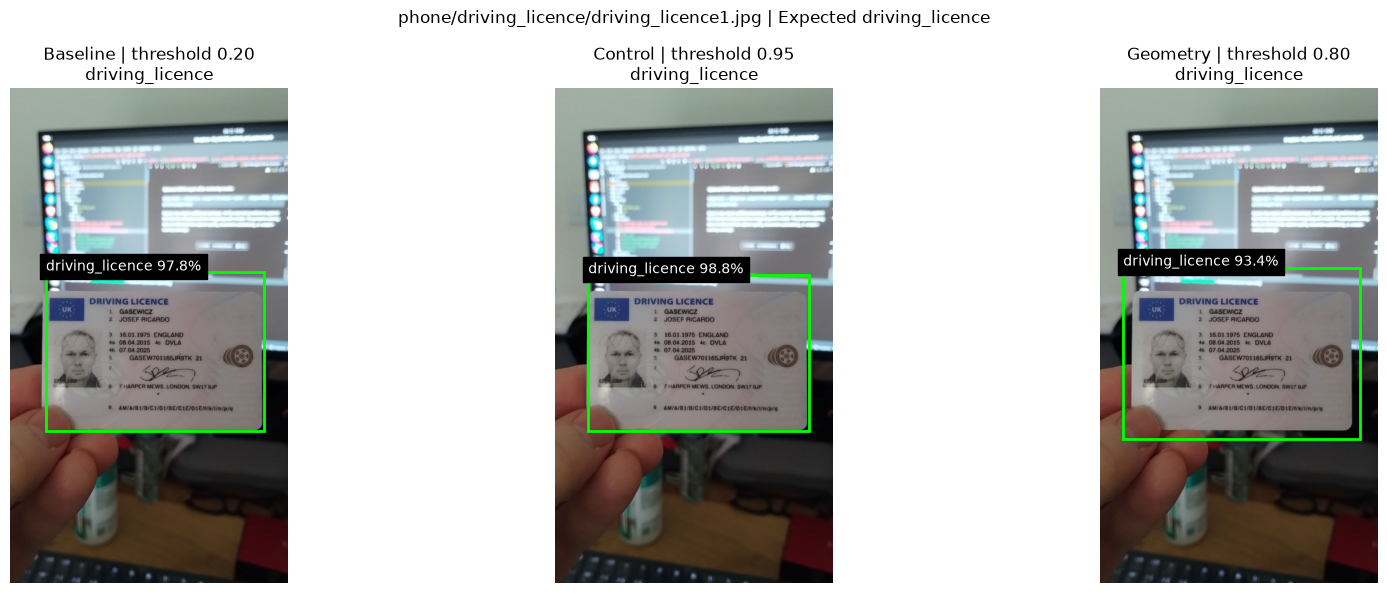

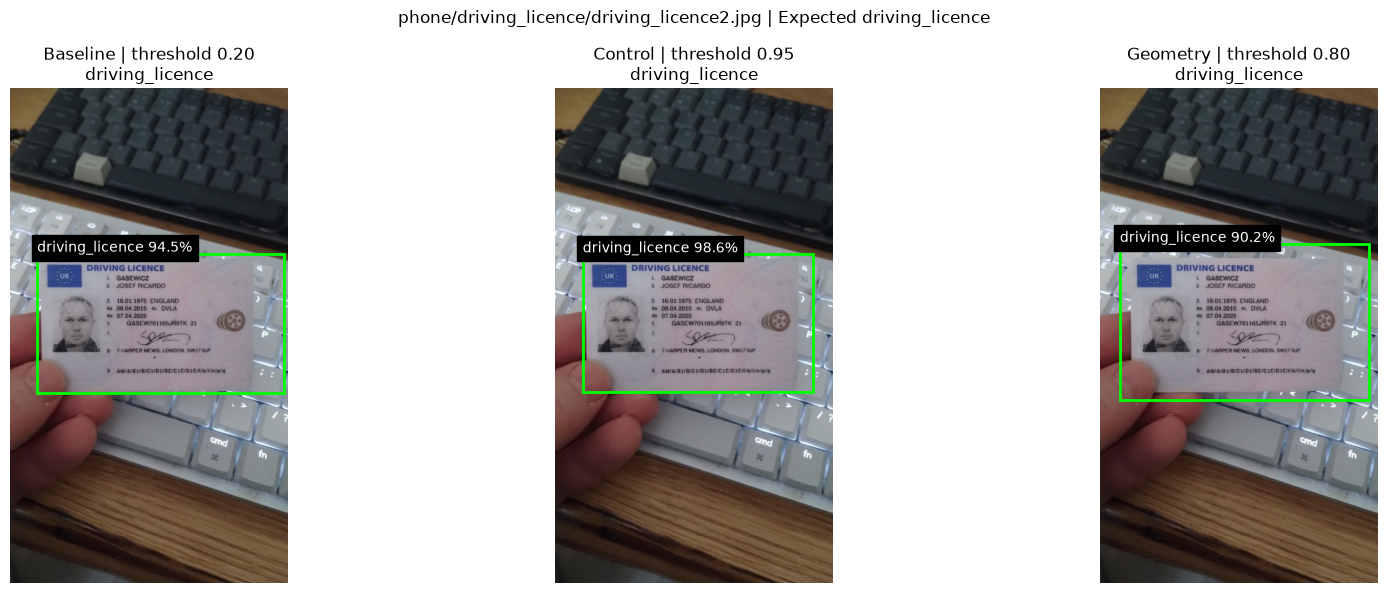

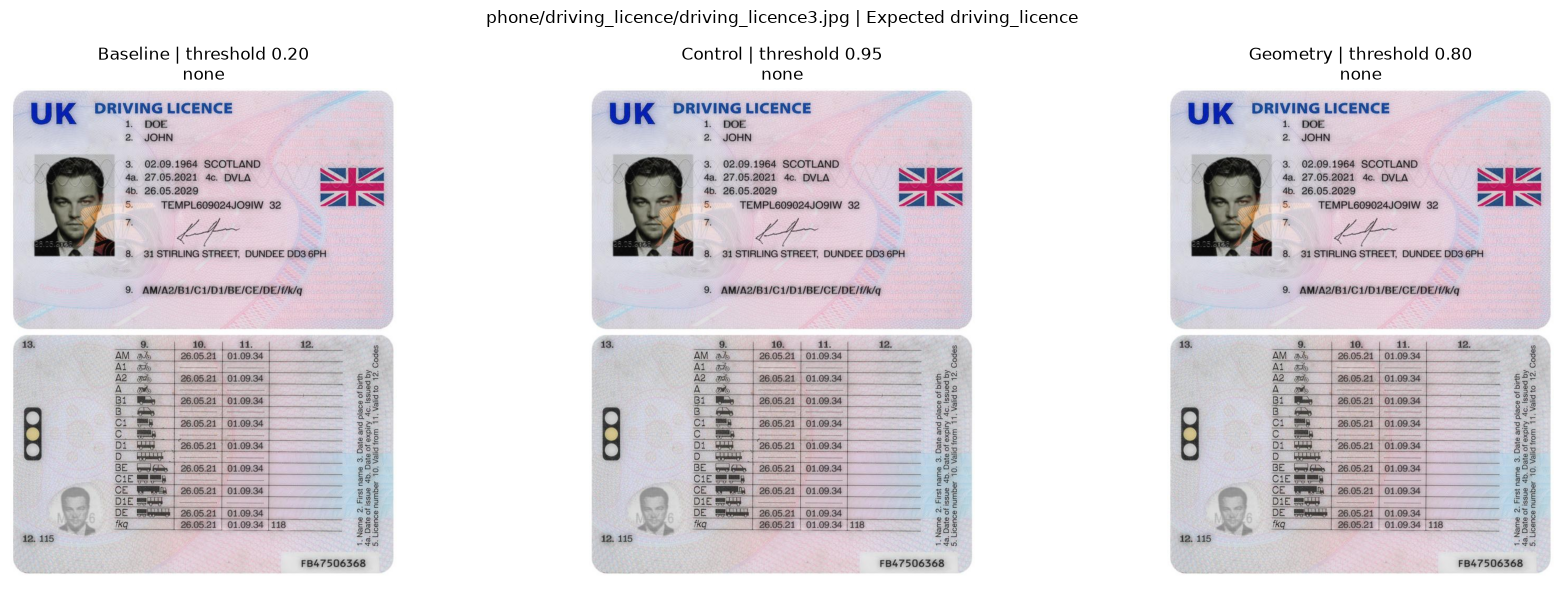

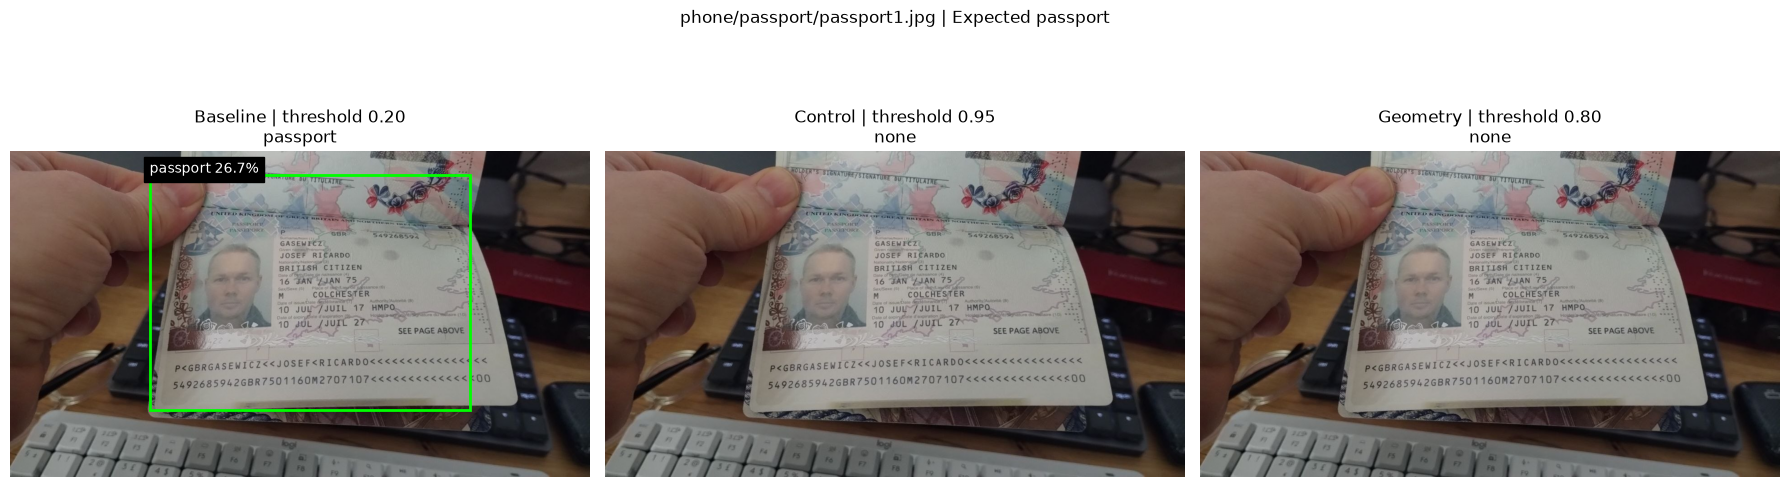

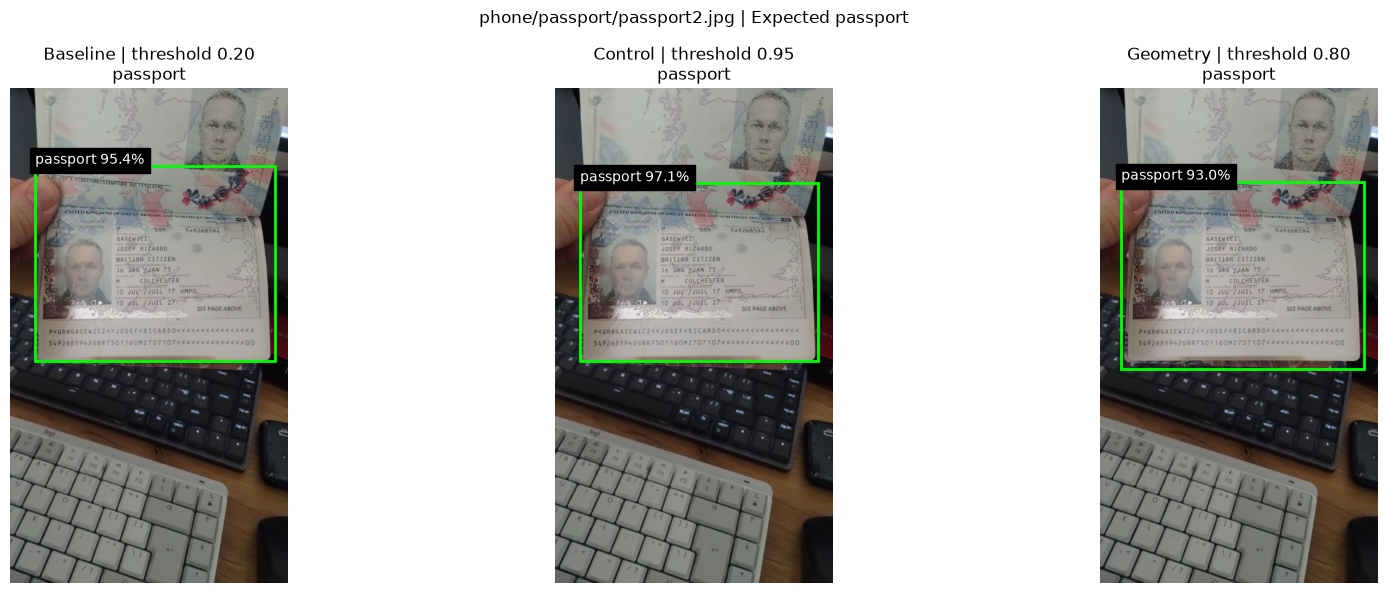

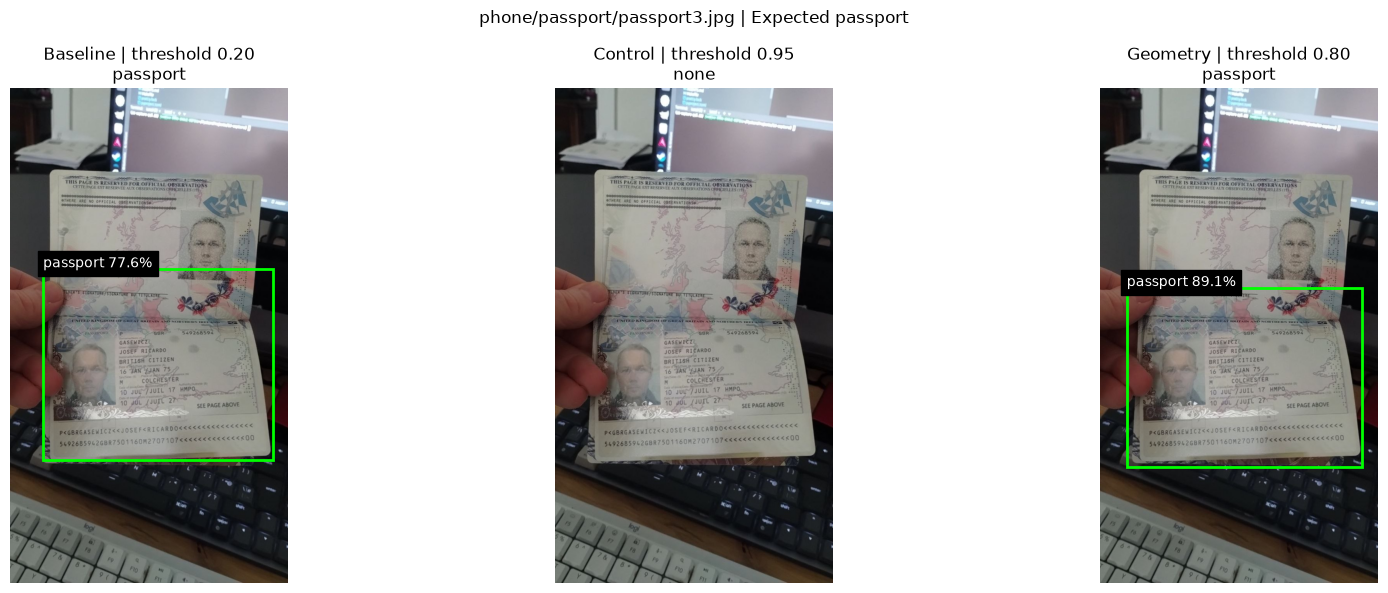

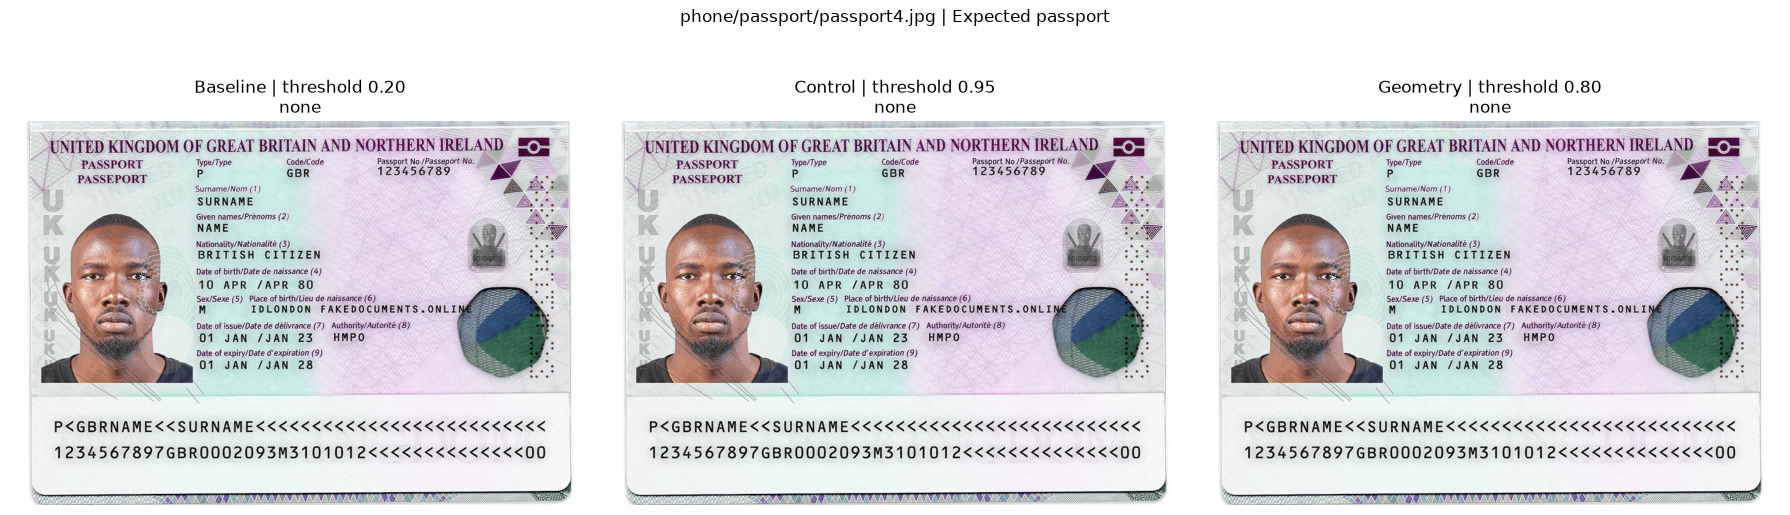

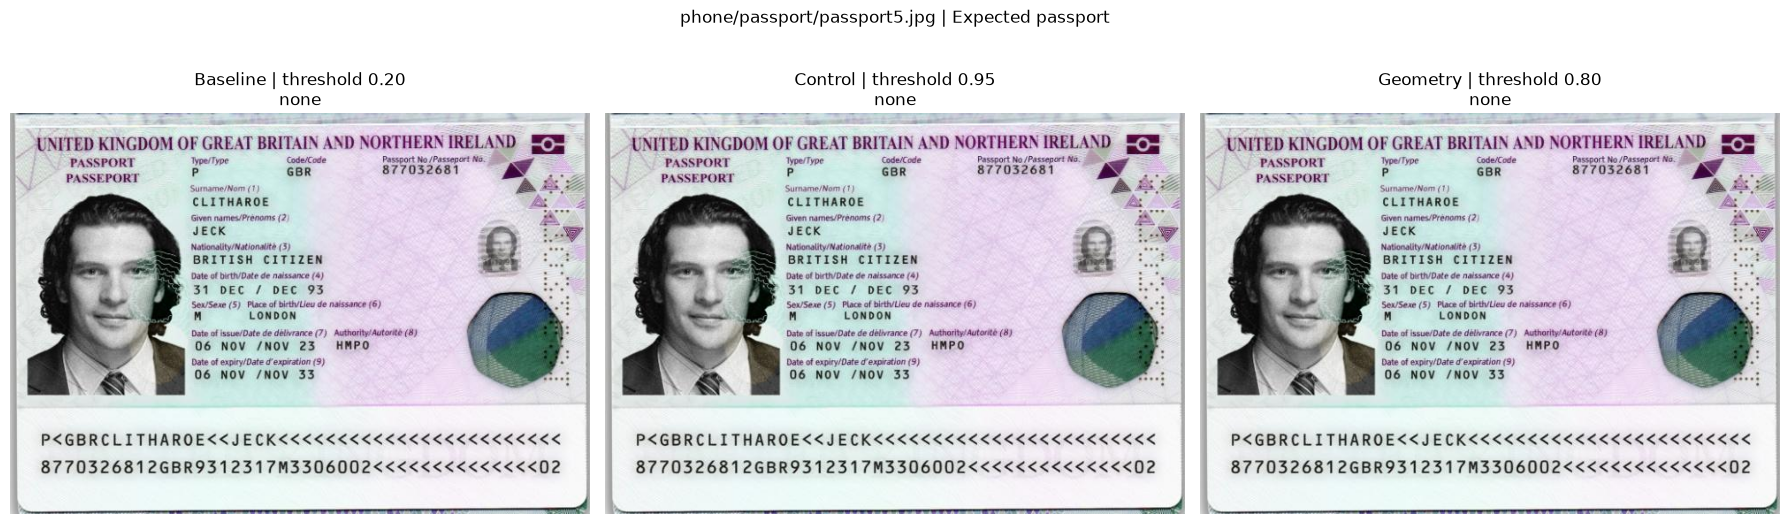

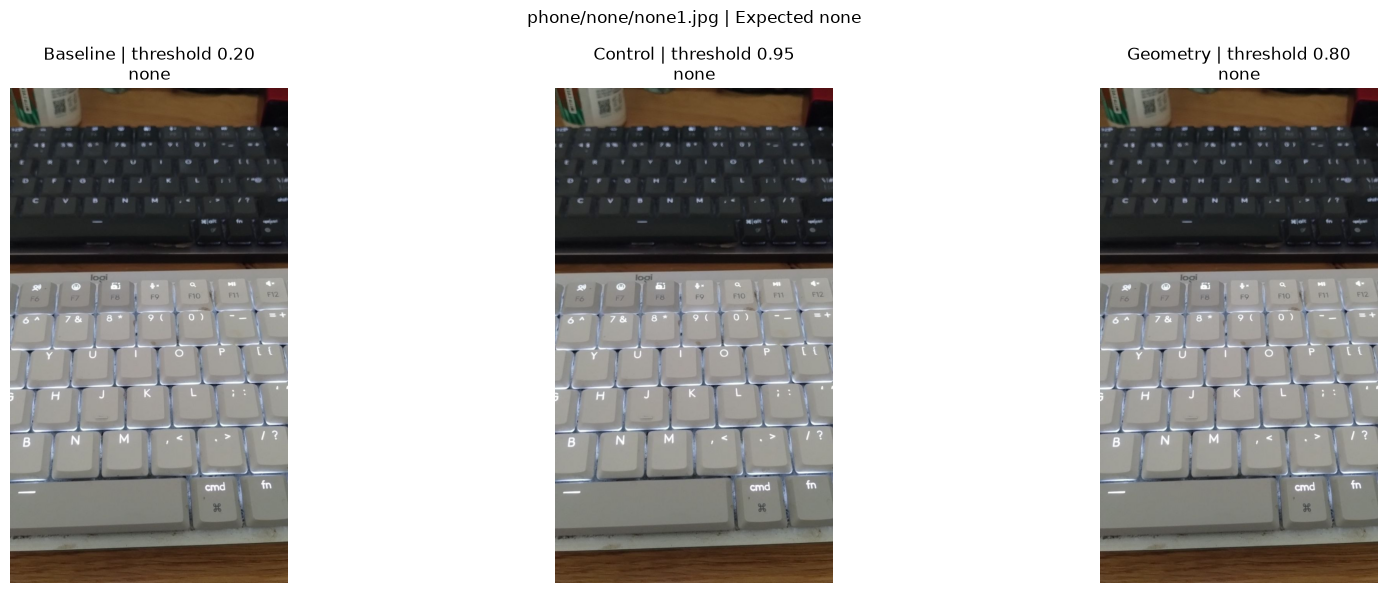

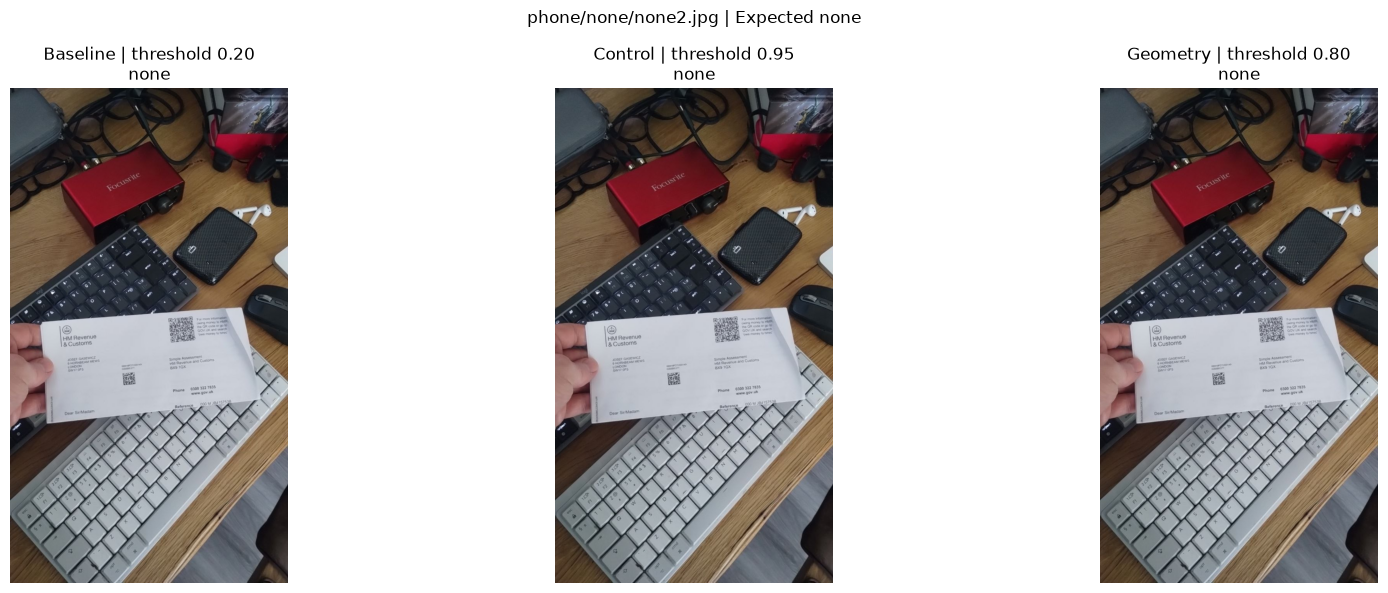

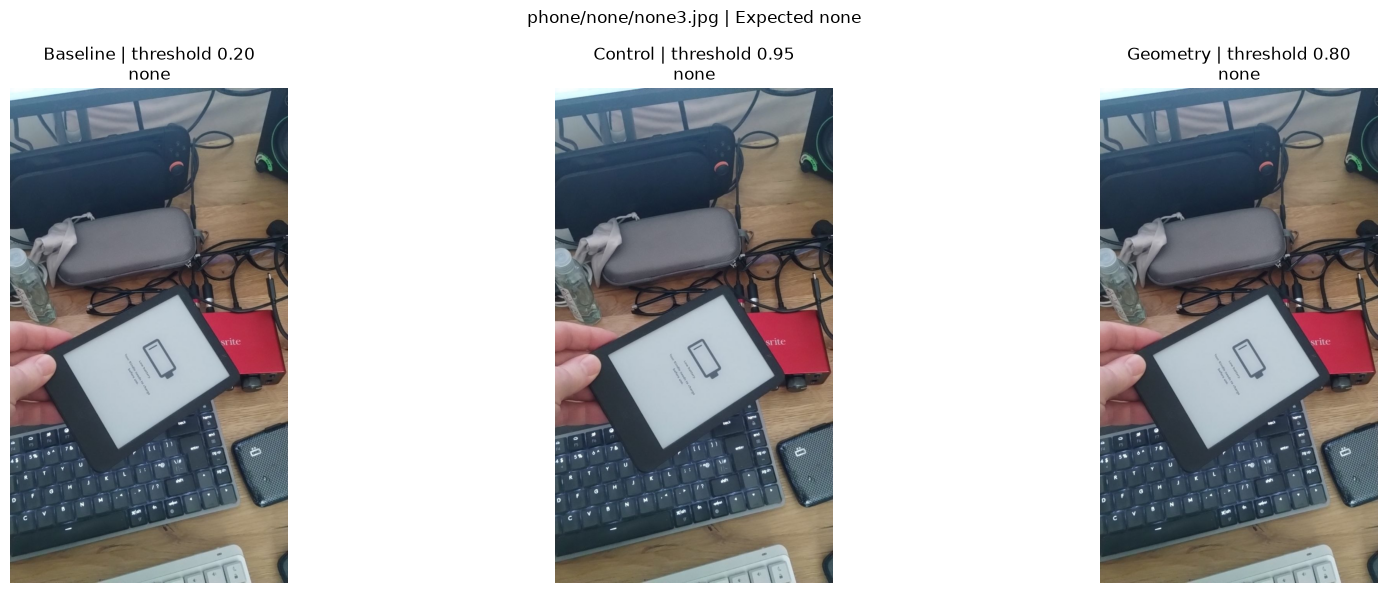

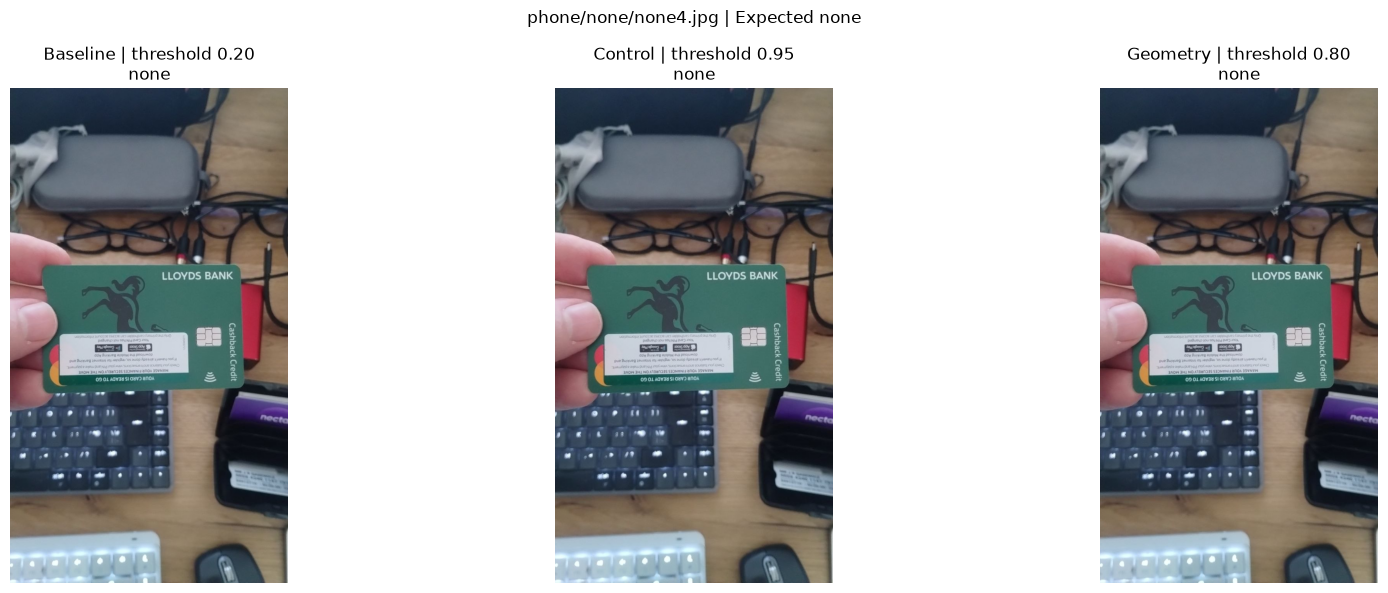

In [5]:
DISPLAY_GROUP = "phone"  # "phone", "negative_fixtures", or "all"
assert DISPLAY_GROUP in {"phone","negative_fixtures","all"}
for sample in qa_samples:
    if DISPLAY_GROUP != "all" and sample["group"] != DISPLAY_GROUP:
        continue
    image = read_bgr(sample["path"])
    fig, axes = plt.subplots(1,len(CHECKPOINTS),figsize=(18,6))
    for ax,(name,checkpoint) in zip(axes,CHECKPOINTS.items()):
        boxes = qa_predictions[(name,sample["key"])]
        result = document_result(boxes)
        ax.imshow(image[:,:,::-1])
        for x1,y1,x2,y2,score,class_id in boxes:
            label = NAMES[int(class_id)]
            color = "lime" if label == sample["expected"] else "red"
            ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor=color,linewidth=2))
            ax.text(x1,max(0,y1-5),f"{label} {score:.1%}",color="white",backgroundcolor="black")
        ax.set_title(f'{name} | threshold {calibrations[name]["threshold"]:.2f}\n{result["document_type"]}')
        ax.axis("off")
    fig.suptitle(f'{sample["key"]} | Expected {sample["expected"]}')
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    del image


## Decide the next experiment

Review all three reports together. Geometry should reduce negative detections without trading away target recall, and should improve over the continued-training control rather than only the frozen original model. Inspect by-source results for hidden regressions.

Do not promote a model based only on these twelve selected fixtures. If geometry fails to improve generalisation, retain the existing model and prioritise independent non-target document designs and capture conditions. Neither this notebook nor notebooks 12–13 update app deployment files or baseline pointers. Candidate ONNX export and parity verification are a separate next step after a satisfactory result.